# PISA 2022: EDA observations

Six systems: ARE, SAU, QAT, JOR, MAR and PSE. Scope: 17 candidate predictors and mathematics achievement. Run cells in order from the project's existing environment. The source student/school Parquet files and dictionary must be available under `data/`.


**Methods and limits:** Initial structure/distribution checks describe the unweighted full sample. Outcome analyses use development schools only, original student weights within systems and equal-system weights for pooling, with statistics calculated separately for ten plausible values. These are development-sample descriptions, not official national estimates. no confidence intervals or significance tests are provided. Correlations are not causal effects or model importance. Retain all 17 candidates. any data-driven selection belongs inside the relevant training folds.


**Sources:** [OECD PISA 2022 database](https://www.oecd.org/en/data/datasets/pisa-2022-database.html). [OECD analysis guidance: weights, senate weights and plausible values](https://www.oecd.org/en/about/programmes/pisa/how-to-prepare-and-analyse-the-pisa-database.html). [PISA 2022 construction of indices](https://www.oecd.org/en/publications/pisa-2022-results-volume-ii_a97db61c-en/full-report/component-15.html).


## 1. Load and identify the data

Read selected columns from the separate questionnaire sources. These Parquet files already contain NaNs from the extraction process. they are not untouched SPSS files. IDs, weights and mathematics PVs are not automatically predictors. Dictionary labels determine analytical types.


In [1]:

# Import the tools for file paths, tables, numerical calculations and plots.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project folder from the current working directory or its parents.
ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
            if (folder / "data/data_dictionary.csv").exists())
# Choose the six systems and the predictor columns used in this EDA.
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]

STUDENT_PREDICTORS = [
    "ESCS", "PAREDINT", "HISEI", "HOMEPOS",
    "ANXMAT", "MATHEFF", "MATHEF21",
    "BELONG", "BULLIED", "DISCLIM", "TEACHSUP"
]
SCHOOL_PREDICTORS = [
    "EDUSHORT", "STAFFSHORT", "MCLSIZE", "STRATIO", "SCHLTYPE", "SCHSIZE"
]
# Keep all 10 mathematics plausible values and the original survey weight columns.
PVS = [f"PV{i}MATH" for i in range(1, 11)]
WEIGHTS = ["W_FSTUWT"] + [f"W_FSTURWT{i}" for i in range(1, 81)]

student_columns = ["CNT", "CNTSCHID", "CNTSTUID"] + STUDENT_PREDICTORS + PVS + WEIGHTS
school_columns = ["CNT", "CNTSCHID"] + SCHOOL_PREDICTORS

print("Student predictors:", len(STUDENT_PREDICTORS))
print("School predictors:", len(SCHOOL_PREDICTORS))
print("Mathematics plausible values:", len(PVS))
print("Survey weights:", len(WEIGHTS))
# Read only the selected columns and systems from the student and school files.
students = pd.read_parquet(
    ROOT / "data/parquet/CY08MSP_STU_QQQ",
    columns=student_columns,
    filters=[("CNT", "in", SYSTEMS)]
)
schools = pd.read_parquet(
    ROOT / "data/parquet/CY08MSP_SCH_QQQ",
    columns=school_columns,
    filters=[("CNT", "in", SYSTEMS)]
)
# Load variable descriptions and documented response codes.
dictionary = pd.read_csv(ROOT / "data/data_dictionary.csv")

print("Student table (rows, columns):", students.shape)
print("School table (rows, columns):", schools.shape)

Student predictors: 11
School predictors: 6
Mathematics plausible values: 10
Survey weights: 81
Student table (rows, columns): (61775, 105)
School table (rows, columns): (1973, 8)


In [2]:
# Preview the records to see how student and school tables are organised.
display(students[["CNT", "CNTSCHID", "CNTSTUID", "ESCS", "ANXMAT"]].head())
display(schools.head())
# Look up descriptions and response labels for the selected predictors.
selected_metadata = dictionary.loc[
    ((dictionary["dataset"] == "student") & dictionary["variable"].isin(STUDENT_PREDICTORS)) |
    ((dictionary["dataset"] == "school") & dictionary["variable"].isin(SCHOOL_PREDICTORS)),
    ["dataset", "variable", "label", "type"]
]
display(selected_metadata)
# Compare sample sizes and the percentage of sampled students in each system.
system_counts = pd.DataFrame({
    "students": students.groupby("CNT").size(),
    "school_records": schools.groupby("CNT").size()
}).reindex(SYSTEMS)
system_counts["student_sample_share_pct"] = system_counts["students"] / len(students) * 100
display(system_counts.round(2))

,CNT,CNTSCHID,CNTSTUID,ESCS,ANXMAT
0,PSE,27500099.0,27500001.0,-0.6594,NaN
1,PSE,27500050.0,27500002.0,-0.7512,0.4067
2,PSE,27500157.0,27500003.0,-0.7349,0.9050
3,PSE,27500213.0,27500004.0,1.6743,NaN
4,PSE,27500038.0,27500005.0,-1.7778,0.4290


,CNT,CNTSCHID,EDUSHORT,STAFFSHORT,MCLSIZE,STRATIO,SCHLTYPE,SCHSIZE
0,PSE,27500001.0,-0.4907,-0.1856,13.0,24.1143,3.0,422.0
1,PSE,27500002.0,0.1423,0.9208,28.0,18.1094,1.0,2318.0
2,PSE,27500003.0,2.9595,4.5007,43.0,21.3750,3.0,684.0
3,PSE,27500004.0,2.9595,1.1244,38.0,16.4390,3.0,337.0
4,PSE,27500005.0,2.1861,0.9208,43.0,24.0606,3.0,794.0


,dataset,variable,label,type
371,school,SCHLTYPE,School type,double
372,school,SCHSIZE,School size (Sum),double
378,school,STRATIO,Student-teacher ratio,double
403,school,STAFFSHORT,Shortage of educational staff (WLE),double
404,school,EDUSHORT,Shortage of educational material (WLE),double
407,school,MCLSIZE,Math class size,double
1421,student,BELONG,Sense of belonging (WLE),double
1422,student,BULLIED,Being bullied (WLE),double
1435,student,DISCLIM,Disciplinary climate in mathematics (WLE),double
1436,student,TEACHSUP,Mathematics Teacher Support (WLE),double


,students,school_records,student_sample_share_pct
CNT,,,
ARE,24600,840,39.82
SAU,6928,193,11.21
QAT,7676,229,12.43
JOR,7799,260,12.62
MAR,6867,178,11.12
PSE,7905,273,12.80


**Observed results: 1. Data overview**

**Observations**

- The selected student table has **61,775 rows and 105 columns**. the school table has **1,973 rows and 8 columns**.
- There are **17 candidate predictors**: 11 from students and six from schools. Remaining columns include identifiers, ten mathematics plausible values and 81 survey weights.
- UAE contributes **24,600 students (39.82% of the selected student sample)** and 840 schools.
- The dictionary distinguishes predictor meanings even when their storage types are numeric.


## 2. Missingness

Counts use students for student predictors and one record per school for school predictors. Missing-code checks use each variable's dictionary entry. No replacement, imputation or deletion occurs. Percentages are unweighted. By-system heatmaps use a common 0–100% scale.


In [3]:
import json

# Identify missing-response labels documented in the data dictionary.
MISSING_LABELS = {"valid skip", "not applicable", "invalid", "no response"}
code_checks = []

# Check each predictor against its own documented missing codes.
for source, table, predictors in [
    ("student", students, STUDENT_PREDICTORS),
    ("school", schools, SCHOOL_PREDICTORS)
]:
    for variable in predictors:
        metadata = dictionary.loc[
            (dictionary["dataset"] == source) &
            (dictionary["variable"] == variable)
        ]
        if len(metadata) != 1:
            raise ValueError(f"Expected one dictionary entry for {source}/{variable}")

        # Read the response labels and extract codes representing missing answers.
        labels = json.loads(metadata.iloc[0]["value_labels"])
        codes = [float(value) for value, label in labels.items()
                 if label.strip().lower() in MISSING_LABELS]
        # Count any coded missing answers that remain and values already stored as NaN.
        code_checks.append({
            "source": source,
            "variable": variable,
            "documented_missing_codes": codes,
            "coded_missing_still_present": int(table[variable].isin(codes).sum()),
            "already_NaN": int(table[variable].isna().sum())
        })

# Display the audit without changing any source values.
missing_code_audit = pd.DataFrame(code_checks)
display(missing_code_audit)

,source,variable,documented_missing_codes,coded_missing_still_present,already_NaN
0,student,ESCS,"[95.0, 97.0, 98.0, 99.0]",0,2432
1,student,PAREDINT,"[9995.0, 9997.0, 9998.0, 9999.0]",0,2659
2,student,HISEI,"[995.0, 997.0, 998.0, 999.0]",0,9017
3,student,HOMEPOS,"[95.0, 97.0, 98.0, 99.0]",0,1764
4,student,ANXMAT,"[95.0, 97.0, 98.0, 99.0]",0,14123
5,student,MATHEFF,"[95.0, 97.0, 98.0, 99.0]",0,13037
6,student,MATHEF21,"[95.0, 97.0, 98.0, 99.0]",0,13837
7,student,BELONG,"[95.0, 97.0, 98.0, 99.0]",0,5714
8,student,BULLIED,"[95.0, 97.0, 98.0, 99.0]",0,5572
9,student,DISCLIM,"[95.0, 97.0, 98.0, 99.0]",0,10455


In [4]:
# Count missing student responses and express them as percentages.
student_missing = pd.DataFrame({
    "missing_students": students[STUDENT_PREDICTORS].isna().sum(),
    "observed_students": students[STUDENT_PREDICTORS].notna().sum(),
    "percent_missing": students[STUDENT_PREDICTORS].isna().mean() * 100
}).sort_values("percent_missing", ascending=False)
student_missing.index.name = "predictor"
display(student_missing.round(2))
# Calculate school missingness with each school counted once.
school_missing = pd.DataFrame({
    "missing_schools": schools[SCHOOL_PREDICTORS].isna().sum(),
    "observed_schools": schools[SCHOOL_PREDICTORS].notna().sum(),
    "percent_missing": schools[SCHOOL_PREDICTORS].isna().mean() * 100
}).sort_values("percent_missing", ascending=False)
school_missing.index.name = "predictor"
display(school_missing.round(2))

,missing_students,observed_students,percent_missing
predictor,,,
ANXMAT,14123,47652,22.86
MATHEF21,13837,47938,22.40
MATHEFF,13037,48738,21.10
TEACHSUP,11140,50635,18.03
DISCLIM,10455,51320,16.92
HISEI,9017,52758,14.60
BELONG,5714,56061,9.25
BULLIED,5572,56203,9.02
PAREDINT,2659,59116,4.30


,missing_schools,observed_schools,percent_missing
predictor,,,
STRATIO,283,1690,14.34
SCHSIZE,221,1752,11.20
MCLSIZE,182,1791,9.22
EDUSHORT,179,1794,9.07
STAFFSHORT,179,1794,9.07
SCHLTYPE,91,1882,4.61


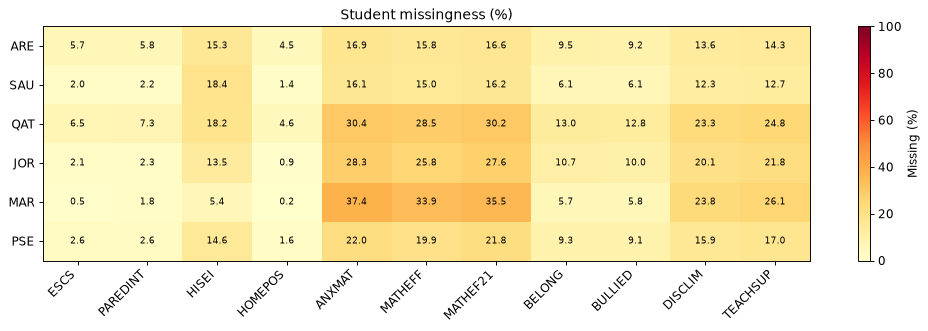

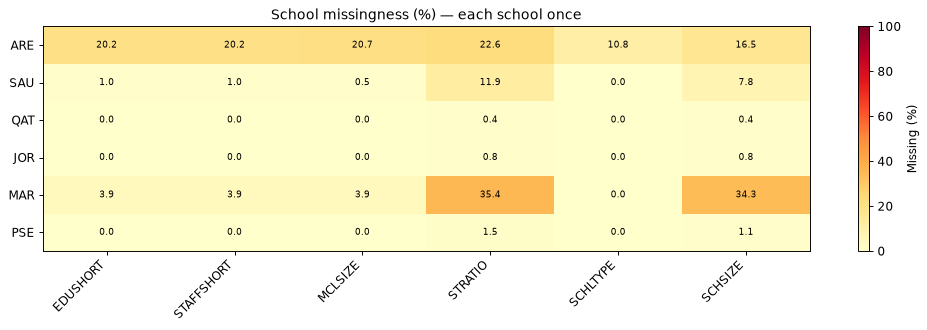

In [5]:
# Calculate missing percentages separately for each system.
student_missing_by_system = students.groupby("CNT")[STUDENT_PREDICTORS].agg(
    lambda column: column.isna().mean() * 100).reindex(SYSTEMS)
school_missing_by_system = schools.groupby("CNT")[SCHOOL_PREDICTORS].agg(
    lambda column: column.isna().mean() * 100).reindex(SYSTEMS)

# Plot the percentages so differences between systems are easier to see.
for title, table in [("Student missingness (%)", student_missing_by_system),
                     ("School missingness (%) — each school once", school_missing_by_system)]:
    fig, ax = plt.subplots(figsize=(12, 4))
    image = ax.imshow(table.to_numpy(), cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(table.columns)), labels=table.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(SYSTEMS)), labels=SYSTEMS)
    for row in range(len(table)):
        for column in range(len(table.columns)):
            value = table.iloc[row, column]
            ax.text(column, row, f"{value:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 60 else "black")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="Missing (%)")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [6]:
# Exact patterns list ALL missing predictors. remaining selected predictors are observed.
for title, table, predictors in [("Students", students, STUDENT_PREDICTORS),
                                  ("Schools", schools, SCHOOL_PREDICTORS)]:
    # Mark missing values and count the number of missing predictors per record.
    mask = table[predictors].isna()
    gap_counts = mask.sum(axis=1).value_counts().sort_index().rename_axis("missing_predictors").to_frame("records")
    gap_counts["percent"] = gap_counts["records"] / len(table) * 100
    # List the exact combinations of missing predictors and count their frequency.
    patterns = mask.apply(lambda row: ", ".join(row.index[row]) if row.any() else "None missing", axis=1)
    pattern_summary = patterns.value_counts().rename_axis("exact_missing_predictors").to_frame("records")
    pattern_summary["percent"] = pattern_summary["records"] / len(table) * 100
    # Display the gap counts and the five most frequent missingness patterns.
    print(title)
    display(gap_counts.round(2))
    with pd.option_context("display.max_colwidth", None):
        display(pattern_summary.head(5).round(2))
    print("Records outside the five displayed patterns:", int(pattern_summary["records"].iloc[5:].sum()))

,records,percent
missing_predictors,,
0,41562,67.28
1,5364,8.68
2,1368,2.21
3,2204,3.57
4,1191,1.93
5,4124,6.68
6,1368,2.21
7,1363,2.21
8,1024,1.66


,records,percent
exact_missing_predictors,,
None missing,41562,67.28
"ANXMAT, MATHEFF, MATHEF21, DISCLIM, TEACHSUP",3675,5.95
HISEI,3328,5.39
"ESCS, PAREDINT, HISEI, HOMEPOS, ANXMAT, MATHEFF, MATHEF21, BELONG, BULLIED, DISCLIM, TEACHSUP",1700,2.75
"ANXMAT, MATHEFF, MATHEF21",1589,2.57


,records,percent
missing_predictors,,
0,1660,84.14
1,34,1.72
2,102,5.17
3,23,1.17
4,32,1.62
5,32,1.62
6,90,4.56


,records,percent
exact_missing_predictors,,
None missing,1660,84.14
"STRATIO, SCHSIZE",98,4.97
"EDUSHORT, STAFFSHORT, MCLSIZE, STRATIO, SCHLTYPE, SCHSIZE",90,4.56
"EDUSHORT, STAFFSHORT, MCLSIZE, STRATIO",32,1.62
"EDUSHORT, STAFFSHORT, MCLSIZE, STRATIO, SCHSIZE",32,1.62


Students
Records outside the five displayed patterns: 9921
Schools
Records outside the five displayed patterns: 61


**Observed results: 2. Missingness**

**Observations**

- None of the 17 selected predictors contain remaining documented missing-answer codes. the unavailable values are already NaN.
- Student-predictor missingness is highest for **ANXMAT (22.86%)**, **MATHEF21 (22.40%)** and **MATHEFF (21.10%)**.
- Counting each school once, **STRATIO is missing in 14.34%** and **SCHSIZE in 11.20%** of school records.
- **41,562 students** have all 11 student predictors observed, while **1,700** lack all 11. These counts concern the selected predictors, not every student-questionnaire field.
- The exact five-variable pattern ANXMAT, MATHEFF, MATHEF21, DISCLIM and TEACHSUP missing together occurs in **3,675 students**. Other selected student predictors are observed in those records.
- **1,660 schools** have all six school predictors observed. **90** lack all six. The exact STRATIO-and-SCHSIZE-only gap occurs in **98 schools**.
- Missingness varies across systems. for example, ANXMAT is missing for **37.44% of Morocco's students**, versus **16.05% in Saudi Arabia**.


## 3. Join schools to students and audit

A validated many-to-one left join on CNT and CNTSCHID retains students. A matched school can still have missing answers. The complete-case calculation is a diagnostic, not a deletion step.


In [7]:
# Use both system and school ID because a school ID alone may repeat across systems.
JOIN_KEYS = ["CNT", "CNTSCHID"]
STUDENT_KEYS = ["CNT", "CNTSTUID"]
PREDICTORS = STUDENT_PREDICTORS + SCHOOL_PREDICTORS

# Check that identifiers are present before joining the tables.
assert not students[JOIN_KEYS + ["CNTSTUID"]].isna().any().any()
assert not schools[JOIN_KEYS].isna().any().any()
assert not students.duplicated(STUDENT_KEYS).any()
assert not schools.duplicated(JOIN_KEYS).any()

# Attach school information to each student and reject duplicate school matches.
joined = students.merge(
    schools,
    on=JOIN_KEYS,
    how="left",
    validate="many_to_one",
    indicator=True
)
print("Linkage status:")
display(joined["_merge"].value_counts().rename("students").to_frame())
# Identify students without a school match and schools unused by the student sample.
unmatched_school_keys = joined.loc[
    joined["_merge"] == "left_only", JOIN_KEYS
].drop_duplicates()

school_usage = schools[JOIN_KEYS].merge(
    students[JOIN_KEYS].drop_duplicates(),
    on=JOIN_KEYS, how="left", validate="one_to_one", indicator=True
)
unused_school_keys = school_usage.loc[
    school_usage["_merge"] == "left_only", JOIN_KEYS
]

# Summarise the linkage checks and record counts.
join_audit = pd.Series({
    "students_before": len(students),
    "students_after": len(joined),
    "row_count_change": len(joined) - len(students),
    "duplicate_students_after": int(joined.duplicated(STUDENT_KEYS).sum()),
    "unmatched_students": int(joined["_merge"].eq("left_only").sum()),
    "unmatched_school_keys": len(unmatched_school_keys),
    "school_records_loaded": len(schools),
    "schools_represented_in_students": len(joined[JOIN_KEYS].drop_duplicates()),
    "school_records_without_selected_students": len(unused_school_keys)
}, name="count")
display(join_audit)

assert len(joined) == len(students)
assert not joined.duplicated(STUDENT_KEYS).any()
# Confirm that the join preserves all original student fields and their values.
original_students = students.set_index(STUDENT_KEYS).sort_index()
joined_students = joined.set_index(STUDENT_KEYS).sort_index()
pd.testing.assert_frame_equal(
    original_students,
    joined_students[original_students.columns]
)

# For matched records, school values must be identical within a school.
# Confirm that every matched student receives the original school values.
matched = joined.loc[joined["_merge"] == "both"]
assert matched.groupby(JOIN_KEYS)[SCHOOL_PREDICTORS].nunique(dropna=False).le(1).all().all()
joined_school_values = matched[JOIN_KEYS + SCHOOL_PREDICTORS].drop_duplicates(JOIN_KEYS)
source_school_values = schools.merge(
    joined_school_values[JOIN_KEYS], on=JOIN_KEYS, how="inner", validate="one_to_one"
)
pd.testing.assert_frame_equal(
    source_school_values.set_index(JOIN_KEYS)[SCHOOL_PREDICTORS].sort_index(),
    joined_school_values.set_index(JOIN_KEYS)[SCHOOL_PREDICTORS].sort_index()
)
print("Verified: original student fields, 10 mathematics PVs, 81 weights and matched school values are preserved.")

# Remove the temporary merge-status column after completing the audit.
data = joined.drop(columns="_merge").copy()
print("Combined table shape:", data.shape)

,students
_merge,
both,61775
left_only,0
right_only,0


students_before                             61775
students_after                              61775
row_count_change                                0
duplicate_students_after                        0
unmatched_students                              0
unmatched_school_keys                           0
school_records_loaded                        1973
schools_represented_in_students              1973
school_records_without_selected_students        0
Name: count, dtype: int64

Linkage status:
Verified: original student fields, 10 mathematics PVs, 81 weights and matched school values are preserved.
Combined table shape: (61775, 111)


In [8]:
# Identify students with observed values for every selected predictor.
complete_case = data[PREDICTORS].notna().all(axis=1)
complete_case_review = data[["CNT"]].assign(complete_case=complete_case)
# Estimate the sample loss from complete-case deletion in each system.
complete_case_by_system = complete_case_review.groupby("CNT").agg(
    students=("complete_case", "size"),
    complete_students=("complete_case", "sum")
).reindex(SYSTEMS)
complete_case_by_system["students_lost_if_dropped"] = (
    complete_case_by_system["students"] - complete_case_by_system["complete_students"]
)
complete_case_by_system["percent_lost_if_dropped"] = (
    complete_case_by_system["students_lost_if_dropped"] / complete_case_by_system["students"] * 100
)
# Show the hypothetical loss while retaining every student in the actual data.
display(complete_case_by_system.round(2))
print("Complete students:", int(complete_case.sum()))
print("Students that would be lost:", int((~complete_case).sum()))
print("Percentage that would be lost:", round((~complete_case).mean() * 100, 2))
print("Actual retained students (unchanged):", len(data))

,students,complete_students,students_lost_if_dropped,percent_lost_if_dropped
CNT,,,,
ARE,24600,13990,10610,43.13
SAU,6928,4218,2710,39.12
QAT,7676,4627,3049,39.72
JOR,7799,4782,3017,38.68
MAR,6867,2499,4368,63.61
PSE,7905,5227,2678,33.88


Complete students: 35343
Students that would be lost: 26432
Percentage that would be lost: 42.79
Actual retained students (unchanged): 61775


**Observed results: 3. Join and audit**

**Observations**

- The many-to-one left join retains **61,775 unique students**, linked to **1,973 schools**.
- There are **zero unmatched students, zero duplicate student keys after the join and zero unused source-school records**.
- The source-value checks confirm preservation of student fields, matched school predictors, all ten mathematics PVs and 81 weights.
- The combined table has **111 columns**.
- Requiring observed values for all 17 predictors would retain **35,343 students** and remove **26,432 (42.79%)**.
- Potential complete-case losses differ: **63.61% in Morocco**, **43.13% in UAE** and **33.88% in PSE**.


## 4. Predictor types and distributions

Use 15 numerical predictors for numerical summaries. SCHLTYPE is nominal and MCLSIZE is ordered class-size bands. Scaled indices may have negative values. Numerical plots omit NaNs. categorical tables include Missing. School summaries count schools once. Boxplot fliers remain in the data.


In [9]:
# Separate numerical predictors from coded school categories.
student_numeric = STUDENT_PREDICTORS.copy()
school_numeric = ["EDUSHORT", "STAFFSHORT", "STRATIO", "SCHSIZE"]
# Summarise observed student values, missingness, distinct values and skewness.
student_description = students[student_numeric].describe().T
student_description["missing"] = students[student_numeric].isna().sum()
student_description["distinct_observed_values"] = students[student_numeric].nunique()
student_description["skew"] = students[student_numeric].skew()
print("Student predictors:")
display(student_description.round(3))

# Summarise numerical school predictors with each school counted once.
school_description = schools[school_numeric].describe().T
school_description["missing"] = schools[school_numeric].isna().sum()
school_description["distinct_observed_values"] = schools[school_numeric].nunique()
school_description["skew"] = schools[school_numeric].skew()
print("School predictors — each school once:")
display(school_description.round(3))

,count,mean,std,min,25%,50%,75%,max,missing,distinct_observed_values,skew
ESCS,59343.0,-0.322,1.210,-6.392,-1.074,-0.022,0.584,5.403,2432,31256,-0.807
PAREDINT,59116.0,14.073,3.035,3.000,12.000,16.000,16.000,16.000,2659,6,-1.901
HISEI,52758.0,55.005,25.233,11.010,29.180,65.010,75.540,88.960,9017,360,-0.416
HOMEPOS,60011.0,-0.766,1.273,-9.235,-1.521,-0.739,0.027,9.302,1764,32683,0.122
ANXMAT,47652.0,0.190,1.151,-2.394,-0.379,0.193,0.777,2.635,14123,395,-0.133
MATHEFF,48738.0,-0.451,1.281,-3.508,-1.141,-0.431,0.046,2.356,13037,3124,-0.055
MATHEF21,47938.0,0.198,1.093,-2.488,-0.516,0.202,0.740,2.914,13837,16613,-0.010
BELONG,56061.0,-0.179,0.930,-3.316,-0.771,-0.338,0.202,2.785,5714,5091,1.006
BULLIED,56203.0,-0.123,1.173,-1.228,-1.228,-0.267,0.741,4.694,5572,7172,0.801
DISCLIM,51320.0,0.022,1.082,-2.555,-0.695,-0.078,0.763,1.851,10455,1960,-0.121


,count,mean,std,min,25%,50%,75%,max,missing,distinct_observed_values,skew
EDUSHORT,1794.0,0.098,1.474,-1.421,-1.421,-0.097,1.248,2.960,179,137,0.518
STAFFSHORT,1794.0,0.498,1.545,-1.459,-0.783,0.430,1.544,4.501,179,275,0.576
STRATIO,1690.0,15.795,8.328,1.000,10.922,14.569,19.269,100.000,283,1489,2.631
SCHSIZE,1752.0,969.521,961.502,1.000,419.750,700.000,1158.250,10476.000,221,1042,3.174


Student predictors:
School predictors — each school once:


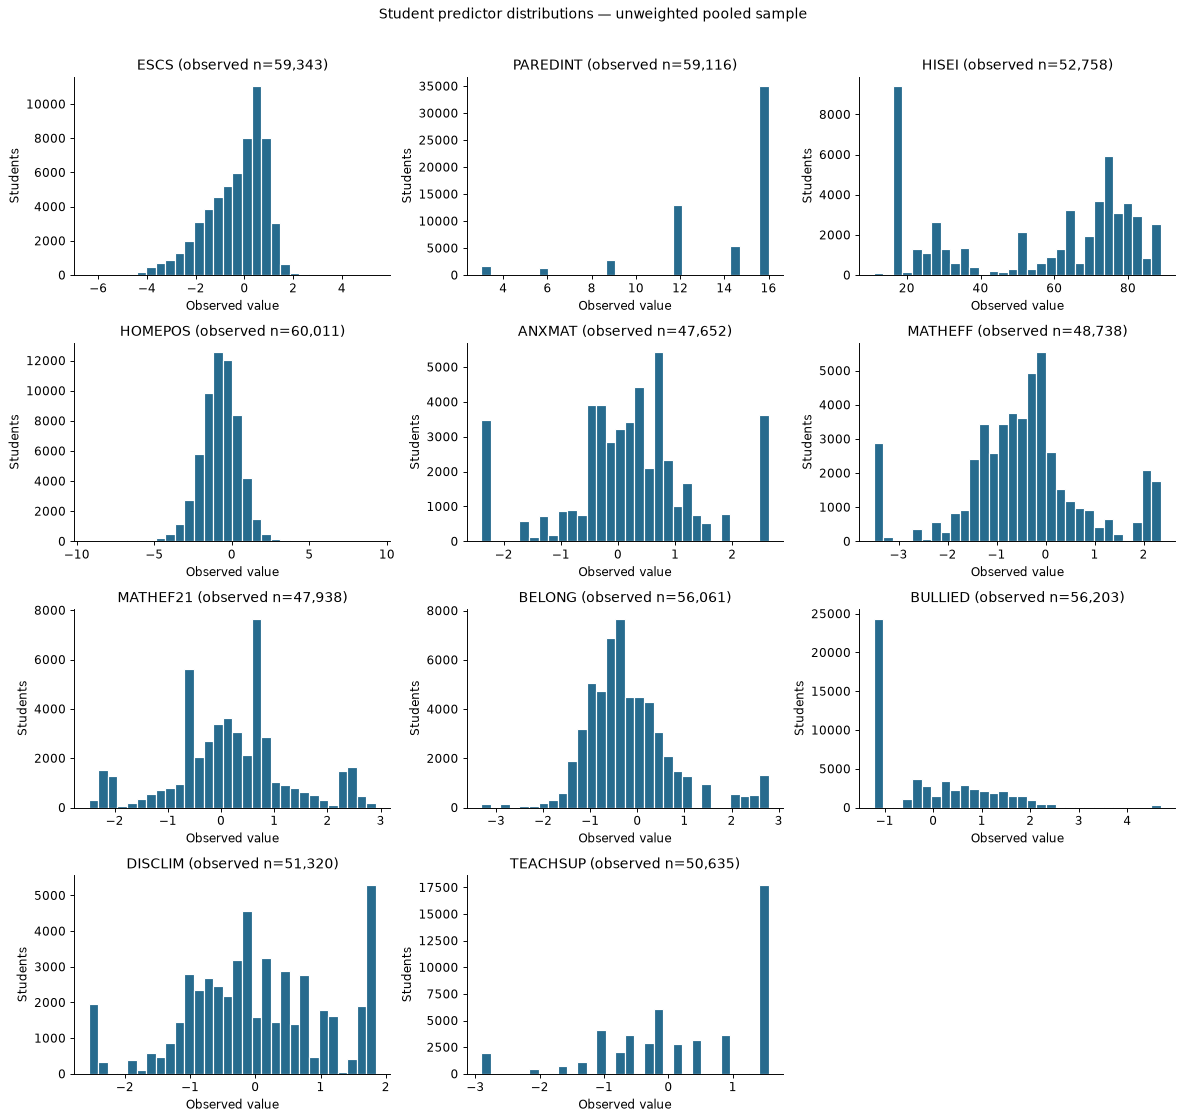

In [10]:
import matplotlib.pyplot as plt

# Create a separate histogram for each numerical student predictor.
fig, axes = plt.subplots(4, 3, figsize=(14, 13))
for ax, variable in zip(axes.flat, student_numeric):
    observed = students[variable].dropna()
    ax.hist(observed, bins=30, color="#276B8E", edgecolor="white")
    ax.set_title(f"{variable} (observed n={len(observed):,})")
    ax.set_xlabel("Observed value")
    ax.set_ylabel("Students")
    ax.spines[["top", "right"]].set_visible(False)
# Hide unused panels because there are fewer predictors than plotting spaces.
for ax in list(axes.flat)[len(student_numeric):]:
    ax.set_visible(False)
fig.suptitle("Student predictor distributions — unweighted pooled sample", y=1.01)
plt.tight_layout()
plt.show()
plt.close(fig)

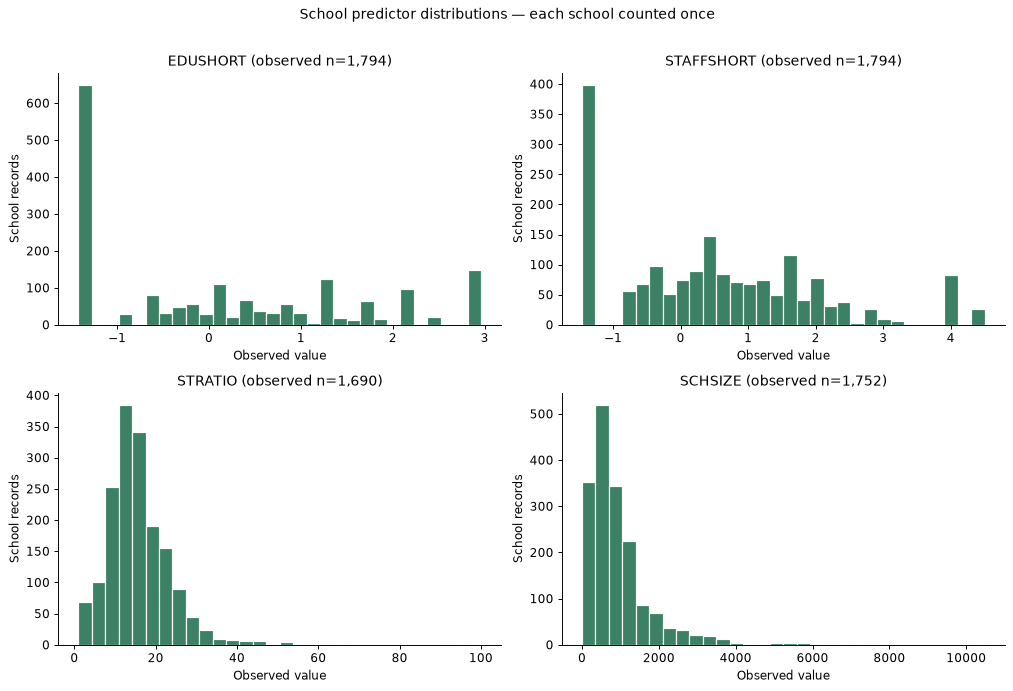

In [11]:
# Plot numerical school predictors using one observation per school.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, variable in zip(axes.flat, school_numeric):
    observed = schools[variable].dropna()
    ax.hist(observed, bins=30, color="#3C8065", edgecolor="white")
    ax.set_title(f"{variable} (observed n={len(observed):,})")
    ax.set_xlabel("Observed value")
    ax.set_ylabel("School records")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("School predictor distributions — each school counted once", y=1.01)
plt.tight_layout()
plt.show()
plt.close(fig)

In [12]:
# Store frequency tables for school type and class-size bands.
category_tables = {}
# Read category labels from the dictionary and include missing responses in the counts.
for variable in ["SCHLTYPE", "MCLSIZE"]:
    metadata = dictionary.loc[
        (dictionary["dataset"] == "school") & (dictionary["variable"] == variable)
    ].iloc[0]
    labels = json.loads(metadata["value_labels"])
    valid_labels = {float(value): label for value, label in labels.items()
                    if label.strip().lower() not in MISSING_LABELS}
    mapped = schools[variable].map(valid_labels)
    assert mapped.notna().eq(schools[variable].notna()).all()
    category_order = list(valid_labels.values()) + ["Missing"]
    counts = mapped.fillna("Missing").value_counts().reindex(category_order, fill_value=0)
    summary = counts.rename_axis(variable).to_frame("schools")
    summary["percent_of_all_schools"] = summary["schools"] / len(schools) * 100
    category_tables[variable] = summary
    print(variable)
    display(summary.round(2))



,schools,percent_of_all_schools
SCHLTYPE,,
Private independent,719,36.44
Private Government-dependent,13,0.66
Public,1150,58.29
Missing,91,4.61


,schools,percent_of_all_schools
MCLSIZE,,
15 students or fewer,126,6.39
16-20 students,162,8.21
21-25 students,353,17.89
26-30 students,389,19.72
31-35 students,280,14.19
36-40 students,185,9.38
41-45 students,135,6.84
46-50 students,73,3.70
More than 50 students,88,4.46


SCHLTYPE
MCLSIZE


,ESCS,PAREDINT,HISEI,HOMEPOS,ANXMAT,MATHEFF,MATHEF21,BELONG,BULLIED,DISCLIM,TEACHSUP
CNT,,,,,,,,,,,
ARE,0.45,16.0,72.24,-0.21,0.17,-0.27,0.36,-0.34,-0.27,0.12,0.15
SAU,-0.10,16.0,68.70,-0.77,0.13,-0.43,0.27,-0.18,-1.23,0.44,0.82
QAT,0.31,16.0,71.39,-0.48,0.19,-0.36,0.24,-0.34,-0.13,-0.07,0.44
JOR,-0.80,14.5,35.34,-1.36,0.19,-0.64,0.03,-0.34,-0.27,-0.27,0.15
MAR,-1.83,12.0,25.23,-1.77,0.37,-0.71,-0.08,-0.34,0.22,-0.34,-0.10
PSE,-0.94,14.5,30.78,-1.43,0.19,-0.64,0.08,-0.33,-0.27,-0.44,0.44


,EDUSHORT,STAFFSHORT,STRATIO,SCHSIZE
CNT,,,,
ARE,-1.42,-0.05,13.82,1001.0
SAU,0.03,0.60,10.81,292.5
QAT,-1.42,-0.59,10.63,707.0
JOR,0.56,0.84,18.72,722.0
MAR,1.25,1.28,26.36,1033.0
PSE,1.25,1.37,18.72,475.5


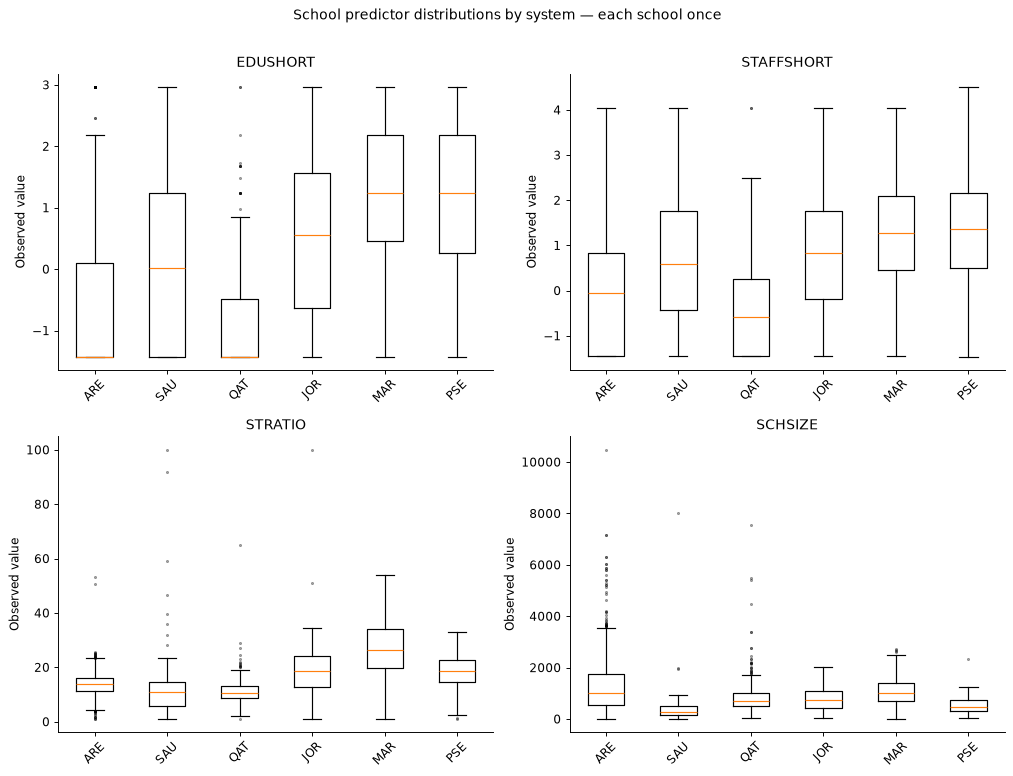

Student predictor medians by system — observed values:
School predictor medians by system — each school once:


In [13]:
# Compare observed medians across systems before interpreting the pooled distributions.
print("Student predictor medians by system — observed values:")
display(students.groupby("CNT")[student_numeric].median().reindex(SYSTEMS).round(2))
print("School predictor medians by system — each school once:")
display(schools.groupby("CNT")[school_numeric].median().reindex(SYSTEMS).round(2))
# Use boxplots to compare school distributions and unusual values across systems.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, variable in zip(axes.flat, school_numeric):
    values = [schools.loc[schools["CNT"] == system, variable].dropna()
              for system in SYSTEMS]
    ax.boxplot(values, tick_labels=SYSTEMS, showfliers=True,
               flierprops={"marker": ".", "markersize": 3, "alpha": 0.45})
    ax.set_title(variable)
    ax.set_ylabel("Observed value")
    ax.tick_params(axis="x", labelrotation=45)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("School predictor distributions by system — each school once", y=1.01)
plt.tight_layout()
plt.show()
plt.close(fig)

**Focused source checks for unusual school values**

Inspect reported enrolment and teacher inputs without modifying official indices. Arithmetic consistency does not establish real-world correctness. The bounded-ratio calculation below is a diagnostic hypothesis, not a verified 2022 production rule. Missing inputs must not silently count as successful comparisons.


In [14]:
# Load the original enrolment and teacher fields needed to investigate unusual values.
school_source_columns = [
    "CNT", "CNTSCHID", "SCHSIZE", "STRATIO", "TOTAT",
    "SC002Q01TA", "SC002Q02TA", "SC018Q01TA01", "SC018Q01TA02"
]
school_value_checks = pd.read_parquet(
    ROOT / "data/parquet/CY08MSP_SCH_QQQ",
    columns=school_source_columns,
    filters=[("CNT", "in", SYSTEMS)]
)
# Compare sampled student counts with the school information.
student_counts = students.groupby(["CNT", "CNTSCHID"]).size().rename("sampled_students")
school_value_checks = school_value_checks.merge(
    student_counts, on=["CNT", "CNTSCHID"], how="left", validate="one_to_one"
)
# Inspect very small schools, high ratios and the five largest reported schools.
large_school_ids = school_value_checks.nlargest(5, "SCHSIZE").index
school_flag = (
    school_value_checks["SCHSIZE"].eq(1) |
    school_value_checks["STRATIO"].eq(100) |
    school_value_checks.index.isin(large_school_ids)
)
display(school_value_checks.loc[school_flag].sort_values(["CNT", "CNTSCHID"]))
# Check whether reported girls and boys add up to the published school size.
enrolment_complete = school_value_checks[["SC002Q01TA", "SC002Q02TA", "SCHSIZE"]].notna().all(axis=1)
enrolment_sum = school_value_checks["SC002Q01TA"] + school_value_checks["SC002Q02TA"]
size_difference = (enrolment_sum - school_value_checks["SCHSIZE"]).abs()
partial_enrolment = (
    school_value_checks["SCHSIZE"].notna() &
    school_value_checks[["SC002Q01TA", "SC002Q02TA"]].isna().any(axis=1)
)
# Compare ratios only when school size and a positive teacher total are available.
ratio_comparable = (
    school_value_checks[["SCHSIZE", "TOTAT", "STRATIO"]].notna().all(axis=1) &
    school_value_checks["TOTAT"].gt(0)
)
raw_ratio = school_value_checks["SCHSIZE"] / school_value_checks["TOTAT"].where(
    school_value_checks["TOTAT"].gt(0)
)
# Test a possible 1 to 100 bound as a diagnostic without changing published ratios.
bounded_ratio_hypothesis = raw_ratio.clip(lower=1, upper=100)
raw_mismatch = ratio_comparable & (raw_ratio - school_value_checks["STRATIO"]).abs().gt(0.001)
bounded_mismatch = ratio_comparable & (bounded_ratio_hypothesis - school_value_checks["STRATIO"]).abs().gt(0.001)

# Count arithmetic inconsistencies and display cases needing closer inspection.
arithmetic_checks = pd.Series({
    "complete_enrolment_cases_compared": int(enrolment_complete.sum()),
    "complete_enrolment_sum_mismatches": int((enrolment_complete & size_difference.gt(0.001)).sum()),
    "published_size_with_partial_enrolment": int(partial_enrolment.sum()),
    "positive_teacher_ratio_cases_compared": int(ratio_comparable.sum()),
    "raw_ratio_mismatches": int(raw_mismatch.sum()),
    "bounded_ratio_hypothesis_mismatches": int(bounded_mismatch.sum()),
    "sampled_students_exceed_published_size": int(
        school_value_checks["sampled_students"].gt(school_value_checks["SCHSIZE"]).sum())
}, name="school_records")
display(arithmetic_checks)
ratio_review = school_value_checks.loc[raw_mismatch, ["CNT", "CNTSCHID", "SCHSIZE", "TOTAT", "STRATIO"]].copy()
ratio_review["unbounded_division"] = raw_ratio.loc[raw_mismatch]
ratio_review["bounded_hypothesis"] = bounded_ratio_hypothesis.loc[raw_mismatch]
display(ratio_review.round(4))

,CNT,CNTSCHID,SCHSIZE,STRATIO,TOTAT,SC002Q01TA,SC002Q02TA,SC018Q01TA01,SC018Q01TA02,sampled_students
1475,ARE,78400345.0,7180.0,18.8947,380.0,3534.0,3646.0,380.0,0.0,34
1503,ARE,78400374.0,10476.0,NaN,NaN,1930.0,8546.0,NaN,NaN,35
1962,ARE,78400833.0,7180.0,18.8947,380.0,3534.0,3646.0,380.0,0.0,30
433,JOR,40000161.0,2007.0,100.0000,20.0,2007.0,0.0,20.0,0.0,25
631,MAR,50400099.0,1.0,1.0000,8.5,NaN,1.0,0.0,17.0,1
870,QAT,63400161.0,7548.0,22.9422,329.0,3766.0,3782.0,329.0,0.0,45
1089,SAU,68200150.0,8000.0,100.0000,2.0,3000.0,5000.0,2.0,NaN,41


complete_enrolment_cases_compared         1663
complete_enrolment_sum_mismatches            0
published_size_with_partial_enrolment       89
positive_teacher_ratio_cases_compared     1690
raw_ratio_mismatches                        11
bounded_ratio_hypothesis_mismatches          0
sampled_students_exceed_published_size       0
Name: school_records, dtype: int64

,CNT,CNTSCHID,SCHSIZE,TOTAT,STRATIO,unbounded_division,bounded_hypothesis
360,JOR,40000088.0,42.0,67.0,1.0,0.6269,1.0
433,JOR,40000161.0,2007.0,20.0,100.0,100.3500,100.0
631,MAR,50400099.0,1.0,8.5,1.0,0.1176,1.0
765,QAT,63400056.0,48.0,80.0,1.0,0.6000,1.0
983,SAU,68200044.0,25.0,29.0,1.0,0.8621,1.0
1063,SAU,68200124.0,14.0,33.0,1.0,0.4242,1.0
1081,SAU,68200142.0,10.0,21.5,1.0,0.4651,1.0
1089,SAU,68200150.0,8000.0,2.0,100.0,4000.0000,100.0
1092,SAU,68200153.0,53.0,59.0,1.0,0.8983,1.0
1500,ARE,78400371.0,15.0,72.0,1.0,0.2083,1.0


**Observed results: 4. Types, distributions and source checks**

**Observations**

- The descriptive grouping uses **15 numerical predictors**, nominal **SCHLTYPE**, and ordered class-size bands **MCLSIZE**.
- School size has observed median **700**, mean **969.52**, minimum **1** and maximum **10,476**. STRATIO has median about **14.57**, mean **15.79** and maximum **100**.
- School-type counts are **1,150 public**, **719 private independent**, **13 private government-dependent** and **91 missing**.
- MCLSIZE most frequently represents **26–30 students (389 schools)**, followed by **21–25 students (353 schools)**. **182** school records are missing this variable.
- Median ESCS is approximately **0.45 in UAE**, **0.31 in Qatar**, **−0.80 in Jordan**, **−0.94 in PSE** and **−1.83 in Morocco**, among observed sample responses.
- In the flagged Morocco record with school size 1, one girl is reported and boys enrolment is unavailable. The largest UAE size equals its reported boys-plus-girls total.
- Among **1,663 complete enrolment comparisons**, none disagree with the published size. Another **89 schools** have a published size despite one unavailable component.
- Among **1,690 comparable positive-teacher ratio records**, **11** disagree with unbounded SCHSIZE/TOTAT division. All fit the tested 1–100 bounded calculation within rounding tolerance.


## 5. Evaluation setup : preserve the agreed assignments

The exact school assignments are stored in this notebook's metadata. Load them by identifiers rather than drawing a new split. Around 20% of schools within each system are reserved for final school testing. five grouped development folds are retained.

Six transfer experiments each hold out one full system. Only development schools from the other five systems enter fitting/tuning, with five inner source-system validation folds. Reserved school-test records never enter fitting. This conservative protocol uses fewer source schools than full-source leave-one-system-out evaluation.

Earlier full-sample predictor EDA and all-system development outcome EDA mean country targets are not wholly unseen throughout the research. Do not tune global transfer features/hyperparameters using these descriptive target outcomes. any selection must remain inside source-only nested validation.


In [15]:
import nbformat

# Read the saved school assignments from this notebook to preserve the agreed split.
notebook_path = ROOT / "02_data-analysis/03_eda_observations.ipynb"
frozen_notebook = nbformat.read(notebook_path, as_version=4)
split_manifest = dict(frozen_notebook.metadata["pisa_evaluation_split_manifest"])
SPLIT_SEED = split_manifest["seed"]
TEST_SCHOOL_FRACTION = split_manifest["test_school_fraction"]
N_FOLDS = 5
# Build a table of school partitions and validation folds from the stored metadata.
school_assignments = pd.DataFrame(split_manifest["school_assignments"])
school_assignments["development_fold"] = school_assignments["development_fold"].astype("Int64")
# Check that the saved assignments cover exactly the current school identifiers.
assert not school_assignments.duplicated(JOIN_KEYS).any()
current_keys = set(data[JOIN_KEYS].itertuples(index=False, name=None))
frozen_keys = set(school_assignments[JOIN_KEYS].itertuples(index=False, name=None))
assert current_keys == frozen_keys, "School IDs changed: review the frozen split before proceeding."
# Attach each school assignment to its students while preserving student order.
row_assignments = data[STUDENT_KEYS + ["CNTSCHID"]].merge(
    school_assignments, on=JOIN_KEYS, how="left", validate="many_to_one")
assert row_assignments[STUDENT_KEYS].equals(data[STUDENT_KEYS])
assert row_assignments["school_partition"].notna().all()
# Count schools and students in development and final-test partitions.
school_split_counts = school_assignments.groupby(
    ["CNT", "school_partition"]
).size().unstack(fill_value=0).reindex(SYSTEMS)
student_split_counts = row_assignments.groupby(
    ["CNT", "school_partition"]
).size().unstack(fill_value=0).reindex(SYSTEMS)

split_summary = pd.DataFrame({
    "development_schools": school_split_counts["development"],
    "test_schools": school_split_counts["final_school_test"],
    "development_students": student_split_counts["development"],
    "test_students": student_split_counts["final_school_test"]
})
split_summary["test_school_pct"] = split_summary["test_schools"] / school_split_counts.sum(axis=1) * 100
split_summary["test_student_pct"] = split_summary["test_students"] / student_split_counts.sum(axis=1) * 100
display(split_summary.round(2))
print("Totals:")
display(split_summary.iloc[:, :4].sum().to_frame("count"))

# Show how development schools are allocated across the five validation folds.
school_fold_counts = school_assignments.loc[
    school_assignments["school_partition"] == "development"
].groupby(["CNT", "development_fold"]).size().unstack(fill_value=0).reindex(SYSTEMS)
print("Development schools per validation fold:")
display(school_fold_counts)

,development_schools,test_schools,development_students,test_students,test_school_pct,test_student_pct
CNT,,,,,,
ARE,672,168,19762,4838,20.00,19.67
SAU,154,39,5593,1335,20.21,19.27
QAT,183,46,6002,1674,20.09,21.81
JOR,208,52,6317,1482,20.00,19.00
MAR,142,36,5443,1424,20.22,20.74
PSE,218,55,6356,1549,20.15,19.60


,count
development_schools,1577
test_schools,396
development_students,49473
test_students,12302


development_fold,0,1,2,3,4
CNT,,,,,
ARE,135,135,134,134,134
SAU,31,31,31,31,30
QAT,37,37,37,36,36
JOR,42,42,42,41,41
MAR,29,29,28,28,28
PSE,44,44,44,43,43


Totals:
Development schools per validation fold:


In [16]:
# Convert system and school identifiers into a set for overlap checks.
def school_key_set(assignments):
    return set(assignments[JOIN_KEYS].itertuples(index=False, name=None))

# Find row positions for development students and final-test students.
development_mask = row_assignments["school_partition"].eq("development")
final_school_test_mask = row_assignments["school_partition"].eq("final_school_test")
development_indices = np.flatnonzero(development_mask)
final_school_test_indices = np.flatnonzero(final_school_test_mask)

# Check that development and final-test partitions contain separate schools.
assert not school_key_set(row_assignments.loc[development_mask]) & school_key_set(row_assignments.loc[final_school_test_mask])
assert len(development_indices) + len(final_school_test_indices) == len(data)
assert len(school_assignments) == len(data[JOIN_KEYS].drop_duplicates())

school_cv_splits = []
fold_audits = []
# Use one development fold for validation and the other folds for training.
for fold in range(N_FOLDS):
    validation_mask = development_mask & row_assignments["development_fold"].eq(fold).fillna(False)
    training_mask = development_mask & row_assignments["development_fold"].ne(fold).fillna(False)
    train_indices = np.flatnonzero(training_mask)
    validation_indices = np.flatnonzero(validation_mask)
    # Verify that schools never appear in both training and validation.
    assert not school_key_set(row_assignments.loc[training_mask]) & school_key_set(row_assignments.loc[validation_mask])
    assert not (training_mask & final_school_test_mask).any()
    assert not (validation_mask & final_school_test_mask).any()
    school_cv_splits.append((train_indices, validation_indices))
    fold_audits.append({"fold": fold, "training_students": len(train_indices),
                        "validation_students": len(validation_indices),
                        "training_schools": len(school_key_set(row_assignments.loc[training_mask])),
                        "validation_schools": len(school_key_set(row_assignments.loc[validation_mask]))})
# Check that every development student appears in validation exactly once.
validation_visits = np.concatenate([validation for train, validation in school_cv_splits])
assert np.array_equal(np.sort(validation_visits), development_indices)
display(pd.DataFrame(fold_audits))
print("School CV checks passed: every development student validates once; schools never cross folds; final school test is excluded.")

,fold,training_students,validation_students,training_schools,validation_schools
0,0,39482,9991,1259,318
1,1,39154,10319,1259,318
2,2,39662,9811,1261,316
3,3,39826,9647,1264,313
4,4,39768,9705,1265,312


School CV checks passed: every development student validates once; schools never cross folds; final school test is excluded.


In [17]:
# Store the source and target row positions for each system-transfer evaluation.
system_transfer_splits = {}
transfer_audits = []
inner_transfer_audits = []
# Hold out one whole system and use development students from the other systems.
for target_system in SYSTEMS:
    source_mask = development_mask & row_assignments["CNT"].ne(target_system)
    target_mask = row_assignments["CNT"].eq(target_system)
    source_indices = np.flatnonzero(source_mask)
    target_indices = np.flatnonzero(target_mask)
    assert not (source_mask & target_mask).any()
    assert not (source_mask & final_school_test_mask).any()
    assert not school_key_set(row_assignments.loc[source_mask]) & school_key_set(row_assignments.loc[target_mask])

    # Within the source data, hold out one source system at a time for validation.
    inner_splits = []
    source_systems = [system for system in SYSTEMS if system != target_system]
    for validation_system in source_systems:
        inner_validation_mask = source_mask & row_assignments["CNT"].eq(validation_system)
        inner_train_mask = source_mask & row_assignments["CNT"].ne(validation_system)
        inner_train = np.flatnonzero(inner_train_mask)
        inner_validation = np.flatnonzero(inner_validation_mask)
        assert not (inner_train_mask & inner_validation_mask).any()
        assert not (inner_train_mask & target_mask).any()
        assert not (inner_validation_mask & target_mask).any()
        assert not school_key_set(row_assignments.loc[inner_train_mask]) & school_key_set(row_assignments.loc[inner_validation_mask])
        inner_splits.append((inner_train, inner_validation))
        inner_transfer_audits.append({
            "outer_target": target_system, "inner_validation_system": validation_system,
            "training_students": len(inner_train), "validation_students": len(inner_validation)
        })
    # Check that inner validation covers the source students exactly once.
    inner_validation_visits = np.concatenate([validation for train, validation in inner_splits])
    assert np.array_equal(np.sort(inner_validation_visits), source_indices)
    system_transfer_splits[target_system] = {
        "source_indices": source_indices,
        "test_indices": target_indices,
        "inner_cv": inner_splits
    }
    transfer_audits.append({
        "held_out_system": target_system,
        "source_systems": ", ".join(source_systems),
        "source_development_students": len(source_indices),
        "source_development_schools": len(school_key_set(row_assignments.loc[source_mask])),
        "held_out_students": len(target_indices),
        "held_out_schools": len(school_key_set(row_assignments.loc[target_mask])),
        "source_inner_folds": len(inner_splits)
    })
# Display the planned allocations and checks without fitting a model.
transfer_summary = pd.DataFrame(transfer_audits)
inner_transfer_summary = pd.DataFrame(inner_transfer_audits)
display(transfer_summary)
print("Nested source-system CV allocation (30 inner folds):")
print("Inner source-validation folds:", len(inner_transfer_summary))
print("All transfer separation checks passed.")

,held_out_system,source_systems,source_development_students,source_development_schools,held_out_students,held_out_schools,source_inner_folds
0,ARE,"SAU, QAT, JOR, MAR, PSE",29711,905,24600,840,5
1,SAU,"ARE, QAT, JOR, MAR, PSE",43880,1423,6928,193,5
2,QAT,"ARE, SAU, JOR, MAR, PSE",43471,1394,7676,229,5
3,JOR,"ARE, SAU, QAT, MAR, PSE",43156,1369,7799,260,5
4,MAR,"ARE, SAU, QAT, JOR, PSE",44030,1435,6867,178,5
5,PSE,"ARE, SAU, QAT, JOR, MAR",43117,1359,7905,273,5


Nested source-system CV allocation (30 inner folds):
Inner source-validation folds: 30
All transfer separation checks passed.


In [18]:
# Use the frozen school assignments to select records for further EDA.
frozen_school_assignments = pd.DataFrame(split_manifest["school_assignments"])
assert school_key_set(frozen_school_assignments) == school_key_set(data)
assert not frozen_school_assignments.duplicated(JOIN_KEYS).any()
relationship_assignments = data[JOIN_KEYS].merge(
    frozen_school_assignments[JOIN_KEYS + ["school_partition"]],
    on=JOIN_KEYS, how="left", validate="many_to_one"
)
relationship_development_mask = relationship_assignments["school_partition"].eq("development")
# Keep development students for relationship and achievement analyses.
development_data = data.loc[relationship_development_mask.to_numpy()].copy()
development_school_keys = frozen_school_assignments.loc[
    frozen_school_assignments["school_partition"] == "development", JOIN_KEYS
]
# Select the corresponding school records without repeating schools.
development_schools = schools.merge(
    development_school_keys, on=JOIN_KEYS, how="inner", validate="one_to_one"
)
# Confirm that final-test schools are excluded from these development tables.
assert not school_key_set(development_data) & school_key_set(
    frozen_school_assignments.loc[frozen_school_assignments["school_partition"] == "final_school_test"]
)
print("Development students:", len(development_data))
print("Development schools:", len(development_schools))

Development students: 49473
Development schools: 1577


**Observed results: 5. Evaluation setup**

**Observations**

- The frozen school split assigns **1,577 schools / 49,473 students** to development and **396 schools / 12,302 students** to the final school test.
- Around 20% of schools within each system are reserved. Student percentages vary with school sample sizes.
- Five development folds keep entire country-and-school groups together. Every development student appears in one validation fold.
- Six system-transfer experiments each hold out one system. Each has five inner source-system validation folds.
- Transfer fitting/tuning uses only development schools in the other five systems. reserved school-test records never enter fitting in either protocol.
- The notebook stores the exact school assignments in metadata and reloads them by identifiers.


## 6. Predictor relationships : development records only

Student/student correlations count students. school/school correlations count each development school once. Use pairwise observed values without filling missing data. Report paired n. no significance tests or automatic feature selection are performed. Numerical code distances are not assigned to SCHLTYPE or MCLSIZE.


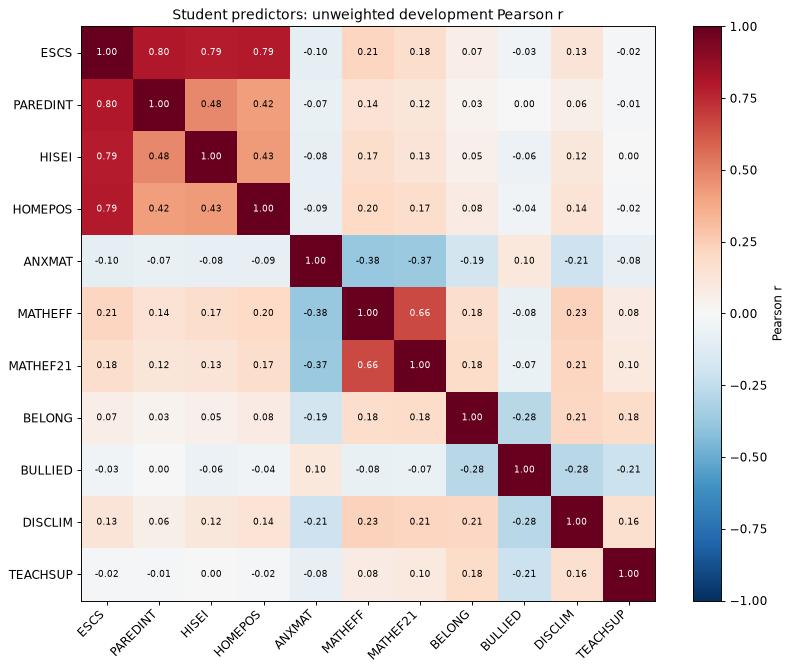

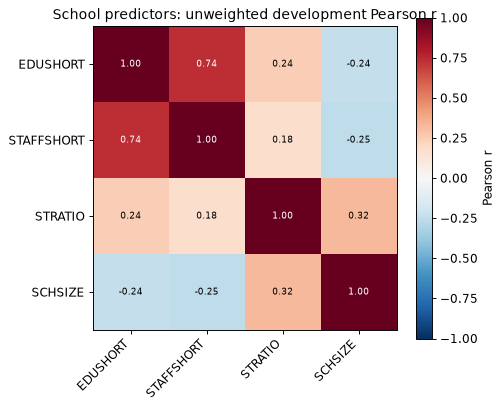

In [19]:
# Calculate pairwise Pearson correlations using observed development values.
student_corr = development_data[student_numeric].corr(method="pearson", min_periods=3)
school_corr = development_schools[school_numeric].corr(method="pearson", min_periods=3)
# Mark observed entries to count how many records support each correlation.
student_observed = development_data[student_numeric].notna().astype("int64")
school_observed = development_schools[school_numeric].notna().astype("int64")
student_pair_n = student_observed.T.dot(student_observed)
school_pair_n = school_observed.T.dot(school_observed)

# Display student and school correlation heatmaps on a common scale.
for title, correlation in [("Student predictors", student_corr), ("School predictors", school_corr)]:
    fig, ax = plt.subplots(figsize=(10, 8) if len(correlation) > 5 else (6, 5))
    image = ax.imshow(correlation.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation)), labels=correlation.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(correlation)), labels=correlation.index)
    for row in range(len(correlation)):
        for column in range(len(correlation)):
            value = correlation.iloc[row, column]
            ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > 0.65 else "black")
    ax.set_title(title + ": unweighted development Pearson r")
    fig.colorbar(image, ax=ax, label="Pearson r")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


In [20]:
# Select predictor pairs for a closer comparison across systems.
relationship_pairs = [
    ("student", "ESCS", "HOMEPOS"),
    ("student", "MATHEFF", "MATHEF21"),
    ("school", "EDUSHORT", "STAFFSHORT"),
    ("school", "STRATIO", "SCHSIZE")
]
relationship_rows = []
# Compare linear Pearson correlation with rank-based Spearman correlation.
for level, a, b in relationship_pairs:
    table = development_data if level == "student" else development_schools
    for system in ["Pooled"] + SYSTEMS:
        subset = table if system == "Pooled" else table.loc[table["CNT"] == system]
        pair = subset[[a, b]].dropna()
        valid = len(pair) >= 3 and pair[a].nunique() > 1 and pair[b].nunique() > 1
        pearson = pair.corr().loc[a, b] if valid else float("nan")
        spearman = pair.rank(method="average").corr().loc[a, b] if valid else float("nan")
        relationship_rows.append({
            "level": level, "A": a, "B": b, "system": system,
            "paired_n": len(pair), "Pearson_r": pearson, "Spearman_rho": spearman
        })
# Collect the pooled and system-specific results in one table.
selected_relationships = pd.DataFrame(relationship_rows)
with pd.option_context("display.max_rows", None):
    display(selected_relationships.round(3))

,level,A,B,system,paired_n,Pearson_r,Spearman_rho
0,student,ESCS,HOMEPOS,Pooled,47575,0.790,0.797
1,student,ESCS,HOMEPOS,ARE,18665,0.688,0.699
2,student,ESCS,HOMEPOS,SAU,5497,0.694,0.702
3,student,ESCS,HOMEPOS,QAT,5614,0.728,0.773
4,student,ESCS,HOMEPOS,JOR,6196,0.771,0.752
5,student,ESCS,HOMEPOS,MAR,5420,0.760,0.738
6,student,ESCS,HOMEPOS,PSE,6183,0.753,0.711
7,student,MATHEFF,MATHEF21,Pooled,38066,0.664,0.623
8,student,MATHEFF,MATHEF21,ARE,16402,0.692,0.646
9,student,MATHEFF,MATHEF21,SAU,4693,0.656,0.610


**Observed results: 6. Predictor relationships**

**Observations**

- Correlations use **49,473 development students** for student predictors and **1,577 development schools** for school predictors, with smaller pairwise-observed samples where values are missing.
- ESCS has Pearson correlations of approximately **0.800 with PAREDINT**, **0.790 with HOMEPOS** and **0.786 with HISEI**.
- MATHEFF and MATHEF21 correlate at approximately **0.664** in the pooled development sample.
- EDUSHORT and STAFFSHORT correlate at approximately **0.736**, counting each development school once.
- STRATIO–SCHSIZE Pearson correlation is about **0.323 pooled**, while selected within-system values range approximately **0.331–0.787**.
- The selected-pair table also reports rank correlations. for pooled STRATIO–SCHSIZE, Spearman is about **0.466**.


## 7. Equal-system weights and mathematics distributions

OECD describes senate weighting as rescaling weights to equal totals across systems. We chose this for comparative pooled EDA, not because OECD requires it universally. Normalise within included development records. keep W_FSTUWT unchanged. Each system contributes one-sixth of pooled weight.

Calculate weighted statistics separately for all ten mathematics PVs and then average those statistics, not individual PV scores. Distribution SD is spread, not a standard error. These are weighted development-sample descriptions without confidence intervals. Original survey replicate weights are retained but formal replication inference is not implemented.


In [21]:
# Keep a copy of the original weights and check that they are valid and positive.
original_weight_snapshot = development_data["W_FSTUWT"].copy()
assert development_data["W_FSTUWT"].notna().all()
assert np.isfinite(development_data["W_FSTUWT"]).all()
assert development_data["W_FSTUWT"].gt(0).all()

# Divide each weight by its system total so every system contributes equal total weight.
system_weight_total = development_data.groupby("CNT")["W_FSTUWT"].transform("sum")
equal_system_weight = development_data["W_FSTUWT"] / system_weight_total

# Store the EDA weights separately alongside the unchanged original weights.
eda_weights = development_data[STUDENT_KEYS + ["W_FSTUWT"]].copy()
eda_weights["equal_system_weight"] = equal_system_weight

# Compare the original weighted system shares with the equal-system shares.
weighting_audit = eda_weights.groupby("CNT").agg(
    development_students=("CNTSTUID", "size"),
    original_weight_sum=("W_FSTUWT", "sum"),
    equal_system_weight_sum=("equal_system_weight", "sum"),
    minimum_equal_weight=("equal_system_weight", "min"),
    maximum_equal_weight=("equal_system_weight", "max")
).reindex(SYSTEMS)
weighting_audit["unweighted_sample_share_pct"] = weighting_audit["development_students"] / len(development_data) * 100
weighting_audit["original_weight_share_pct"] = weighting_audit["original_weight_sum"] / weighting_audit["original_weight_sum"].sum() * 100
weighting_audit["equal_system_share_pct"] = weighting_audit["equal_system_weight_sum"] / weighting_audit["equal_system_weight_sum"].sum() * 100

display(weighting_audit[["development_students", "original_weight_share_pct", "equal_system_share_pct"]].round(2))
# Check that each system has total weight one and the original weights are unchanged.
assert np.allclose(weighting_audit["equal_system_weight_sum"], 1.0)
assert np.isclose(equal_system_weight.sum(), len(SYSTEMS))
assert equal_system_weight.gt(0).all()
pd.testing.assert_series_equal(development_data["W_FSTUWT"], original_weight_snapshot)
print("Verified: each system contributes 1/6; original student weights are unchanged.")

,development_students,original_weight_share_pct,equal_system_share_pct
CNT,,,
ARE,19762,5.76,16.67
SAU,5593,29.28,16.67
QAT,6002,1.69,16.67
JOR,6317,13.54,16.67
MAR,5443,41.54,16.67
PSE,6356,8.20,16.67


Verified: each system contributes 1/6; original student weights are unchanged.


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Match all 10 mathematics plausible values to the EDA weights by student ID.
achievement_data = development_data[STUDENT_KEYS + ["CNTSCHID"] + PVS].merge(
    eda_weights[STUDENT_KEYS + ["W_FSTUWT", "equal_system_weight"]],
    on=STUDENT_KEYS, how="left", validate="one_to_one"
)
# Check row counts, available scores, positive weights and final-test exclusion.
assert len(achievement_data) == len(development_data)
assert achievement_data[PVS].notna().all().all()
assert np.isfinite(achievement_data[PVS].to_numpy()).all()
assert achievement_data[["W_FSTUWT", "equal_system_weight"]].notna().all().all()
assert achievement_data[["W_FSTUWT", "equal_system_weight"]].gt(0).all().all()
assert not school_key_set(achievement_data) & school_key_set(
    frozen_school_assignments.loc[frozen_school_assignments["school_partition"] == "final_school_test"]
)
print("Development students:", len(achievement_data))
print("Mathematics plausible values per student:", len(PVS))
print("Outcome and weight availability checks passed.")
achievement_pv_rows = []
# Calculate weighted score summaries for each system and the equal-system pool.
for system in SYSTEMS + ["Equal-system pooled"]:
    subset = achievement_data if system == "Equal-system pooled" else achievement_data.loc[
        achievement_data["CNT"] == system
    ]
    weight_column = "equal_system_weight" if system == "Equal-system pooled" else "W_FSTUWT"
    weights = subset[weight_column]
    # Summarise each plausible value separately instead of averaging student scores.
    for pv in PVS:
        values = subset[pv]
        mean = np.average(values, weights=weights)
        variance = np.average((values - mean) ** 2, weights=weights)
        achievement_pv_rows.append({
            "system": system, "PV": pv, "students": len(subset),
            "weighted_mean": mean, "weighted_SD": np.sqrt(variance)
        })
achievement_by_pv = pd.DataFrame(achievement_pv_rows)
# Average the descriptive statistics across the 10 plausible values.
achievement_summary = achievement_by_pv.groupby("system", sort=False).agg(
    students=("students", "first"),
    mean_across_10_PVs=("weighted_mean", "mean"),
    average_distribution_SD=("weighted_SD", "mean"),
    minimum_PV_mean=("weighted_mean", "min"),
    maximum_PV_mean=("weighted_mean", "max")
)
display(achievement_summary.round(2))


,students,mean_across_10_PVs,average_distribution_SD,minimum_PV_mean,maximum_PV_mean
system,,,,,
ARE,19762,432.36,101.90,431.69,432.89
SAU,5593,388.31,65.85,387.14,389.13
QAT,6002,412.01,90.21,410.97,413.02
JOR,6317,360.62,62.24,359.24,361.58
MAR,5443,364.03,63.55,363.25,364.46
PSE,6356,365.77,66.06,364.98,366.99
Equal-system pooled,49473,387.18,81.13,386.86,387.48


Development students: 49473
Mathematics plausible values per student: 10
Outcome and weight availability checks passed.


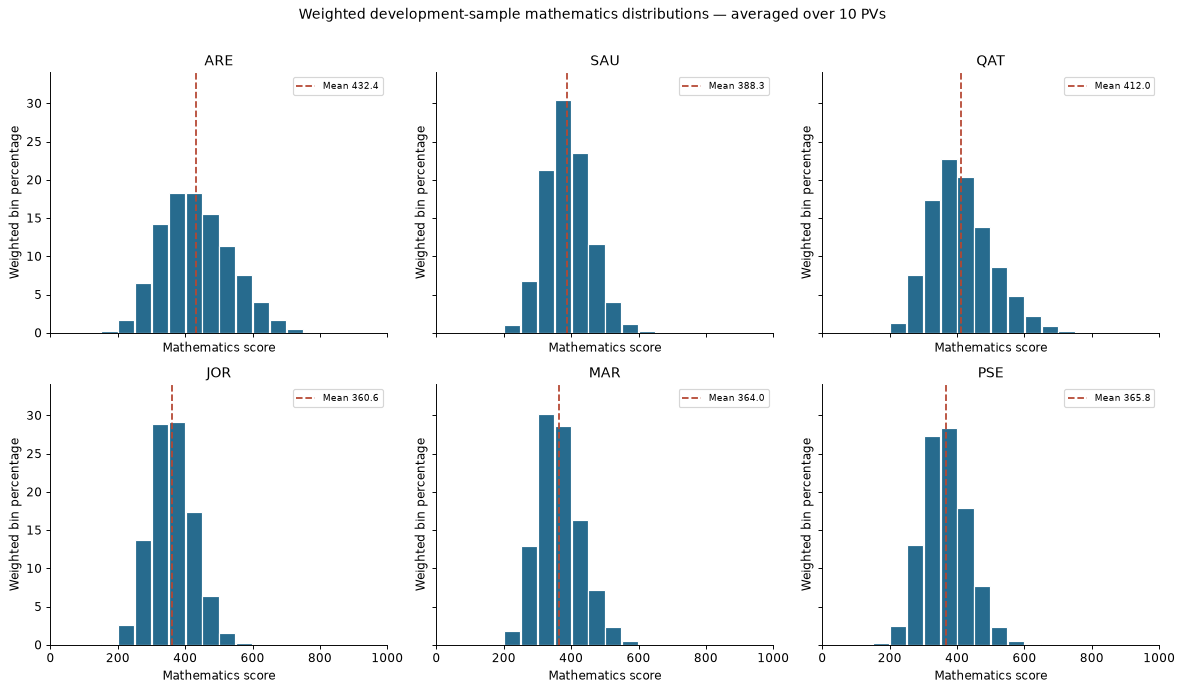

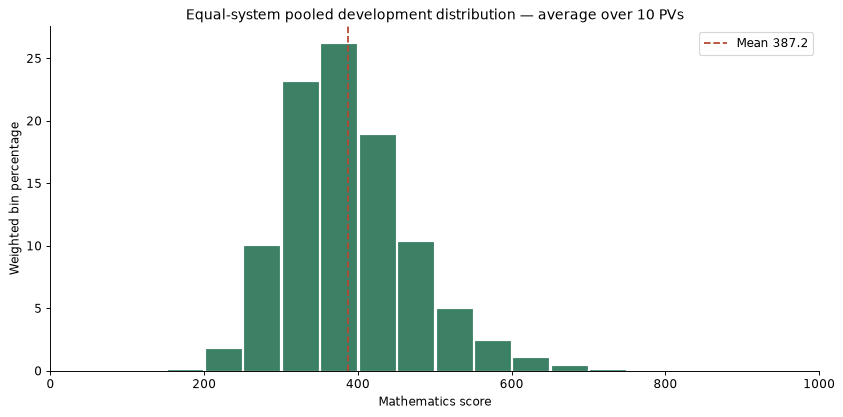

All weighted bin distributions sum to 100%.


In [23]:
# Use the same 50-point score intervals for all systems and plausible values.
score_edges = np.arange(0, 1001, 50)
score_centres = (score_edges[:-1] + score_edges[1:]) / 2
assert achievement_data[PVS].min().min() >= score_edges[0]
assert achievement_data[PVS].max().max() <= score_edges[-1]

# Calculate a weighted distribution for each plausible value before averaging the bins.
achievement_distributions = {}
for system in SYSTEMS + ["Equal-system pooled"]:
    subset = achievement_data if system == "Equal-system pooled" else achievement_data.loc[
        achievement_data["CNT"] == system
    ]
    weight_column = "equal_system_weight" if system == "Equal-system pooled" else "W_FSTUWT"
    weights = subset[weight_column]
    pv_distributions = []
    for pv in PVS:
        weighted_counts, edges = np.histogram(subset[pv], bins=score_edges, weights=weights)
        percentages = weighted_counts / weights.sum() * 100
        assert np.isclose(percentages.sum(), 100)
        pv_distributions.append(percentages)
    achievement_distributions[system] = np.mean(pv_distributions, axis=0)

# Collect the bin percentages and check that each distribution sums to 100 percent.
histogram_table = pd.DataFrame(achievement_distributions)
histogram_table.insert(0, "score_interval", [
    f"[{int(left)}, {int(right)})" if right < score_edges[-1]
    else f"[{int(left)}, {int(right)}]"
    for left, right in zip(score_edges[:-1], score_edges[1:])
])
print("All weighted bin distributions sum to 100%.")
assert np.allclose(histogram_table.drop(columns="score_interval").sum(), 100)
assert np.allclose(
    achievement_distributions["Equal-system pooled"],
    np.mean([achievement_distributions[system] for system in SYSTEMS], axis=0)
)
# Plot all six systems with the same axis scales for easier comparison.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
maximum_bin_pct = max(achievement_distributions[system].max() for system in SYSTEMS)
for ax, system in zip(axes.flat, SYSTEMS):
    ax.bar(score_centres, achievement_distributions[system], width=48,
           color="#276B8E", edgecolor="white")
    mean = achievement_summary.loc[system, "mean_across_10_PVs"]
    ax.axvline(mean, color="#B54732", linestyle="--", label=f"Mean {mean:.1f}")
    ax.set_title(system)
    ax.set_xlim(score_edges[0], score_edges[-1])
    ax.set_ylim(0, maximum_bin_pct * 1.12)
    ax.set_xlabel("Mathematics score")
    ax.set_ylabel("Weighted bin percentage")
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Weighted development-sample mathematics distributions — averaged over 10 PVs", y=1.01)
plt.tight_layout()
plt.show()
plt.close(fig)

# Plot the equal-system pooled distribution and mark its weighted mean.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(score_centres, achievement_distributions["Equal-system pooled"], width=48,
       color="#3C8065", edgecolor="white")
pooled_mean = achievement_summary.loc["Equal-system pooled", "mean_across_10_PVs"]
ax.axvline(pooled_mean, color="#B54732", linestyle="--", label=f"Mean {pooled_mean:.1f}")
ax.set(xlim=(score_edges[0], score_edges[-1]), xlabel="Mathematics score",
       ylabel="Weighted bin percentage", title="Equal-system pooled development distribution — average over 10 PVs")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
plt.close(fig)

**Observed results: 7. Weights and achievement distributions**

**Observations**

- Equal-system weights sum to the same total within each development system, giving each **16.67% of pooled weight**. Original W_FSTUWT and replicate weights remain unchanged.
- OECD describes this equal-total approach as senate weighting. Selecting it for our comparative pooled EDA is a project choice, not a universal OECD requirement.
- Weighted means averaged over ten PV-specific calculations are approximately **432.36 UAE**, **388.31 Saudi Arabia**, **412.01 Qatar**, **360.62 Jordan**, **364.03 Morocco** and **365.77 PSE**.
- The equal-system pooled mean is approximately **387.18**.
- Average PV-specific distribution SDs are approximately **101.90 in UAE**, **90.21 in Qatar**, and **62–66 in the other systems**. Pooled SD is approximately **81.13**.
- Each plotted distribution averages ten PV-specific weighted bin-percentage vectors. Common 50-point bins cover every observed development PV and sum to 100%.


## 8. Numerical predictor–achievement relationships

Calculate weighted Pearson r separately for each mathematics PV and combine the coefficients. Within systems use W_FSTUWT. For pooling, re-normalise on each predictor's eligible records so differing missingness does not change equal-system contribution. Report paired students and distinct schools.

School-predictor/outcome relationships here describe students attending those schools, not independent school observations. All-system development outcomes are visible to this descriptive analysis, so do not use them for global transfer-model selection. Associations are unadjusted and are not causal effects, model importance or a performance ranking.


In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Define Pearson correlation with weights so observations can contribute unequally.
def weighted_correlation(x, y, weights):
    # Convert inputs to numerical arrays and check that their lengths and values are valid.
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    weights = np.asarray(weights, dtype=float)
    assert len(x) == len(y) == len(weights)
    assert len(x) >= 3
    assert np.isfinite(x).all() and np.isfinite(y).all()
    assert np.isfinite(weights).all() and (weights > 0).all()
    # Rescale weights to sum to one before calculating weighted means and variances.
    weights = weights / weights.sum()
    x_centred = x - np.sum(weights * x)
    y_centred = y - np.sum(weights * y)
    x_variance = np.sum(weights * x_centred ** 2)
    y_variance = np.sum(weights * y_centred ** 2)
    # Return NaN when either variable is constant because correlation is undefined.
    if x_variance <= 0 or y_variance <= 0:
        return float("nan")
    # Divide weighted covariance by the product of the weighted standard deviations.
    covariance = np.sum(weights * x_centred * y_centred)
    return covariance / np.sqrt(x_variance * y_variance)

# Check the function with perfectly positive, perfectly negative and constant examples.
assert np.isclose(weighted_correlation([1, 2, 3], [2, 4, 6], [1, 2, 1]), 1)
assert np.isclose(weighted_correlation([1, 2, 3], [6, 4, 2], [1, 2, 1]), -1)
assert np.isnan(weighted_correlation([1, 1, 1], [1, 2, 3], [1, 1, 1]))
print("Weighted-correlation checks passed.")

Weighted-correlation checks passed.


In [25]:
# Use numerical predictors and check that the analysis uses development records only.
numerical_outcome_predictors = student_numeric + school_numeric
assert development_data[PVS].notna().all().all()
assert np.isfinite(development_data[PVS].to_numpy()).all()
assert not school_key_set(development_data) & school_key_set(
    frozen_school_assignments.loc[frozen_school_assignments["school_partition"] == "final_school_test"]
)

outcome_association_rows = []
# Calculate each predictor association separately by system and for the pooled sample.
for predictor in numerical_outcome_predictors:
    for system in SYSTEMS + ["Equal-system pooled"]:
        subset = development_data if system == "Equal-system pooled" else development_data.loc[
            development_data["CNT"] == system
        ]
        # Use students with an observed predictor and all mathematics plausible values.
        eligible = subset.dropna(subset=[predictor] + PVS).copy()
        if len(eligible) < 3:
            raise ValueError(f"Too few observed records: {predictor}, {system}")
        # Rebalance the eligible pooled records so each system still has equal total weight.
        if system == "Equal-system pooled":
            if set(eligible["CNT"].unique()) != set(SYSTEMS):
                raise ValueError(f"An equal-six-system estimate is unavailable for {predictor}")
            weights = eligible["W_FSTUWT"] / eligible.groupby("CNT")["W_FSTUWT"].transform("sum")
            assert np.allclose(weights.groupby(eligible["CNT"]).sum().reindex(SYSTEMS), 1)
        else:
            weights = eligible["W_FSTUWT"]
        # Calculate one weighted correlation per plausible value and retain the supporting counts.
        for pv in PVS:
            outcome_association_rows.append({
                "predictor": predictor,
                "predictor_source": "student" if predictor in student_numeric else "school",
                "system": system, "PV": pv,
                "paired_students": len(eligible),
                "distinct_schools": len(eligible[JOIN_KEYS].drop_duplicates()),
                "weighted_r": weighted_correlation(eligible[predictor], eligible[pv], weights)
            })

outcome_associations_by_pv = pd.DataFrame(outcome_association_rows)
assert outcome_associations_by_pv["weighted_r"].notna().all()
assert outcome_associations_by_pv["weighted_r"].abs().le(1 + 1e-10).all()
# Summarise correlations across the 10 plausible values without ranking feature importance.
association_summary = outcome_associations_by_pv.groupby(
    ["predictor", "predictor_source", "system"], sort=False
).agg(
    paired_students=("paired_students", "first"),
    distinct_schools=("distinct_schools", "first"),
    mean_r_over_10_PVs=("weighted_r", "mean"),
    smallest_PV_r=("weighted_r", "min"),
    largest_PV_r=("weighted_r", "max")
).reset_index()
assert outcome_associations_by_pv.groupby(["predictor", "system"]).size().eq(10).all()

# Display pooled results in the original predictor order.
pooled_associations = association_summary.loc[
    association_summary["system"] == "Equal-system pooled"
].set_index("predictor").reindex(numerical_outcome_predictors)
print("Equal-system pooled associations — predictor order, not an importance ranking:")
display(pooled_associations.drop(columns="system").round(3))

,predictor_source,paired_students,distinct_schools,mean_r_over_10_PVs,smallest_PV_r,largest_PV_r
predictor,,,,,,
ESCS,student,47577,1574,0.366,0.362,0.370
PAREDINT,student,47388,1574,0.230,0.226,0.235
HISEI,student,42276,1573,0.376,0.373,0.379
HOMEPOS,student,48107,1574,0.309,0.305,0.312
ANXMAT,student,38217,1570,-0.210,-0.212,-0.206
MATHEFF,student,39078,1572,0.341,0.338,0.344
MATHEF21,student,38415,1572,0.209,0.203,0.212
BELONG,student,44890,1574,0.123,0.119,0.126
BULLIED,student,45012,1574,-0.169,-0.174,-0.166


Equal-system pooled associations — predictor order, not an importance ranking:


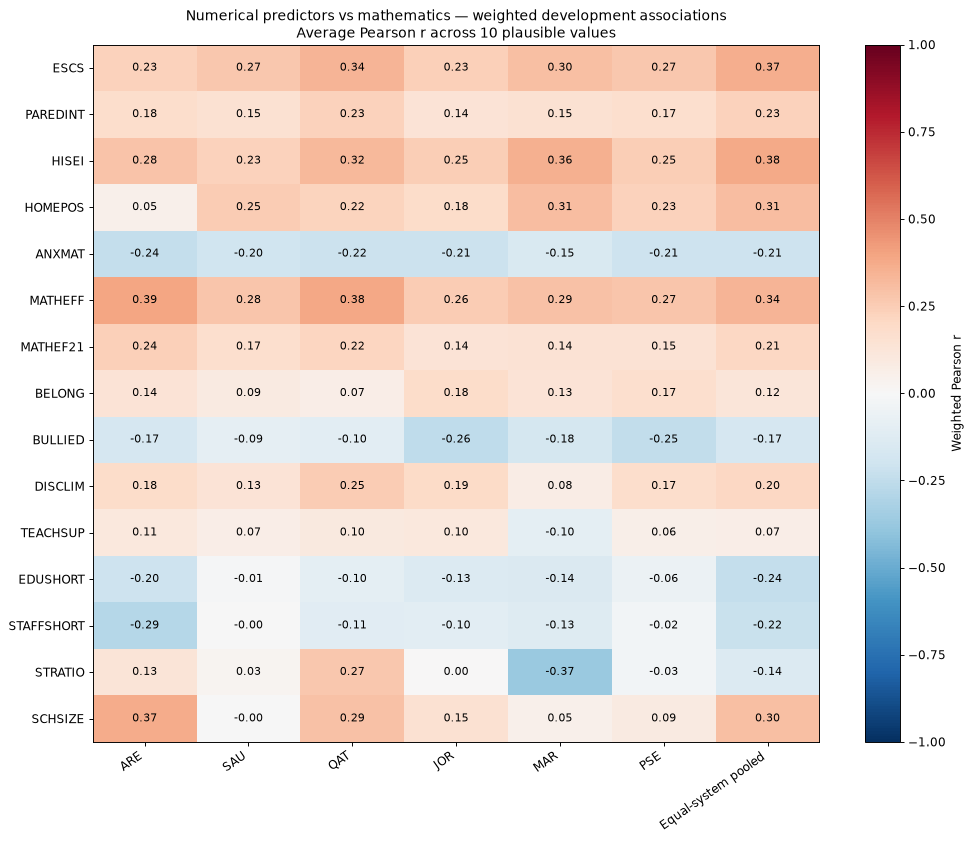

Weighted correlations averaged across 10 PVs:


In [26]:
# Arrange averaged correlations with predictors as rows and systems as columns.
association_matrix = association_summary.pivot(
    index="predictor", columns="system", values="mean_r_over_10_PVs"
).reindex(index=numerical_outcome_predictors, columns=SYSTEMS + ["Equal-system pooled"])
# Retain the student and school counts supporting each association.
association_student_counts = association_summary.pivot(
    index="predictor", columns="system", values="paired_students"
).reindex(index=numerical_outcome_predictors, columns=SYSTEMS + ["Equal-system pooled"])
association_school_counts = association_summary.pivot(
    index="predictor", columns="system", values="distinct_schools"
).reindex(index=numerical_outcome_predictors, columns=SYSTEMS + ["Equal-system pooled"])
print("Weighted correlations averaged across 10 PVs:")




# Plot correlations on a fixed scale from negative one to positive one.
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(association_matrix.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(association_matrix.columns)), labels=association_matrix.columns,
              rotation=35, ha="right")
ax.set_yticks(range(len(association_matrix)), labels=association_matrix.index)
# Write the numerical correlation in each heatmap cell.
for row in range(len(association_matrix)):
    for column in range(len(association_matrix.columns)):
        value = association_matrix.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.65 else "black")
ax.set_title("Numerical predictors vs mathematics — weighted development associations\nAverage Pearson r across 10 plausible values")
fig.colorbar(image, ax=ax, label="Weighted Pearson r")
plt.tight_layout()
plt.show()
plt.close(fig)

**Observed results: 8. Predictor–achievement relationships**

**Observations**

- The analysis combines **1,050 PV-specific weighted correlations**: 15 numerical predictors × six systems plus one pooled group × ten PVs.
- Equal-system pooled correlations are approximately **HISEI 0.376**, **ESCS 0.366**, **MATHEFF 0.341**, **HOMEPOS 0.309** and **SCHSIZE 0.304**.
- ANXMAT is approximately **−0.210**, BULLIED **−0.169**, EDUSHORT **−0.238** and STAFFSHORT **−0.223** in the pooled mixture.
- Pairwise samples differ: HISEI uses **42,276 students**, ESCS **47,577**, MATHEFF **39,078**, and EDUSHORT **45,495 students from 1,434 schools**.
- STRATIO is approximately **−0.136 pooled**, **+0.271 in Qatar** and **−0.372 in Morocco**.
- HOMEPOS is approximately **0.309 pooled** but **0.054 within UAE**. SCHSIZE is approximately **0.304 pooled** but **−0.002 within Saudi Arabia**.


## 9. Overall observations

**Observations**

- Linkage and identifier checks passed. no students were lost or multiplied by the join.
- Missingness is substantial, clustered across predictors and uneven across systems.
- Distributions, variable roles and relationships differ across systems. some unusual source values remain unresolved.
- School and system evaluation boundaries are fixed, while descriptive outcome analyses use development-school records only.
- Equal-system weighting and ten-PV calculations are implemented for achievement EDA.
